In [ ]:
%cd /content/drive/MyDrive/Colab Notebooks/Domain Adaptation


/content/drive/MyDrive/Colab Notebooks/Domain Adaptation


In [ ]:
from torchvision.datasets import ImageFolder

print(ImageFolder("/content/drive/MyDrive/Colab Notebooks/Domain Adaptation/ISIC2019_merged").classes)
print(ImageFolder("/content/drive/MyDrive/Colab Notebooks/Domain Adaptation/fitz_selected").classes)


['ak', 'bcc', 'bkl', 'df', 'mel', 'nv', 'scc']
['ak', 'bcc', 'bkl', 'df', 'mel', 'nv', 'scc']


In [ ]:
from bsp_dann_mobilenetv2 import train_bsp

model = train_bsp(
    source_dir="/content/drive/MyDrive/Colab Notebooks/Domain Adaptation/ISIC2019_merged",
    target_unlabeled_dir="/content/drive/MyDrive/Colab Notebooks/Domain Adaptation/fitz_unlabeled",
    target_labeled_dir="/content/drive/MyDrive/Colab Notebooks/Domain Adaptation/fitz_selected",
    num_classes=7
)


Downloading: "https://download.pytorch.org/models/mobilenet_v2-b0353104.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-b0353104.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 126MB/s]


[Epoch 1/30] Loss: 260.1618
[Epoch 2/30] Loss: 227.6020
[Epoch 3/30] Loss: 219.7585
[Epoch 4/30] Loss: 218.1005
[Epoch 5/30] Loss: 203.9153
[Epoch 6/30] Loss: 205.8224
[Epoch 7/30] Loss: 206.0695
[Epoch 8/30] Loss: 193.1917
[Epoch 9/30] Loss: 194.1032
[Epoch 10/30] Loss: 196.5381
[Epoch 11/30] Loss: 196.5806
[Epoch 12/30] Loss: 193.1003
[Epoch 13/30] Loss: 195.5918
[Epoch 14/30] Loss: 193.6864
[Epoch 15/30] Loss: 192.7293
[Epoch 16/30] Loss: 196.5966
[Epoch 17/30] Loss: 188.1928
[Epoch 18/30] Loss: 197.2075
[Epoch 19/30] Loss: 184.8701
[Epoch 20/30] Loss: 198.2163
[Epoch 21/30] Loss: 178.6392
[Epoch 22/30] Loss: 190.0719
[Epoch 23/30] Loss: 185.2889
[Epoch 24/30] Loss: 181.3270
[Epoch 25/30] Loss: 182.2901
[Epoch 26/30] Loss: 177.8447
[Epoch 27/30] Loss: 184.6185
[Epoch 28/30] Loss: 180.2094
[Epoch 29/30] Loss: 177.9036
[Epoch 30/30] Loss: 178.1181
Training finished.

Classification Report (Target Domain):
              precision    recall  f1-score   support

          ak       0.14  

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [ ]:
import matplotlib.pyplot as plt
import torch
import numpy as np


In [ ]:
def visualize_predictions_per_class(
    model,
    dataset,
    class_names,
    samples_per_class=5,
    device="cuda"
):
    """
    Visualize predictions for each class.

    Args:
        model: trained classifier
        dataset: ImageFolder (Fitz_labeled)
        class_names: list of class names
        samples_per_class: images per class
        device: cuda or cpu
    """
    model.eval()
    class_to_indices = {i: [] for i in range(len(class_names))}

    # collect indices per class
    for idx, (_, label) in enumerate(dataset.samples):
        class_to_indices[label].append(idx)

    for class_idx, indices in class_to_indices.items():
        if len(indices) == 0:
            continue

        chosen = indices[:samples_per_class]

        fig, axes = plt.subplots(
            1, len(chosen),
            figsize=(4 * len(chosen), 4)
        )

        if len(chosen) == 1:
            axes = [axes]

        fig.suptitle(
            f"Class: {class_names[class_idx]}",
            fontsize=16
        )

        for ax, idx in zip(axes, chosen):
            img, gt = dataset[idx]
            img_input = img.unsqueeze(0).to(device)

            with torch.no_grad():
                logits, _ = model(img_input)
                pred = logits.argmax(1).item()

            # unnormalize for display
            img_np = img.permute(1, 2, 0).cpu().numpy()
            img_np = img_np * np.array([0.229, 0.224, 0.225]) + \
                     np.array([0.485, 0.456, 0.406])
            img_np = np.clip(img_np, 0, 1)

            correct = pred == gt
            title_color = "green" if correct else "red"

            ax.imshow(img_np)
            ax.axis("off")
            ax.set_title(
                f"GT: {class_names[gt]}\n"
                f"Pred: {class_names[pred]}",
                color=title_color,
                fontsize=12
            )

        plt.show()


In [ ]:
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

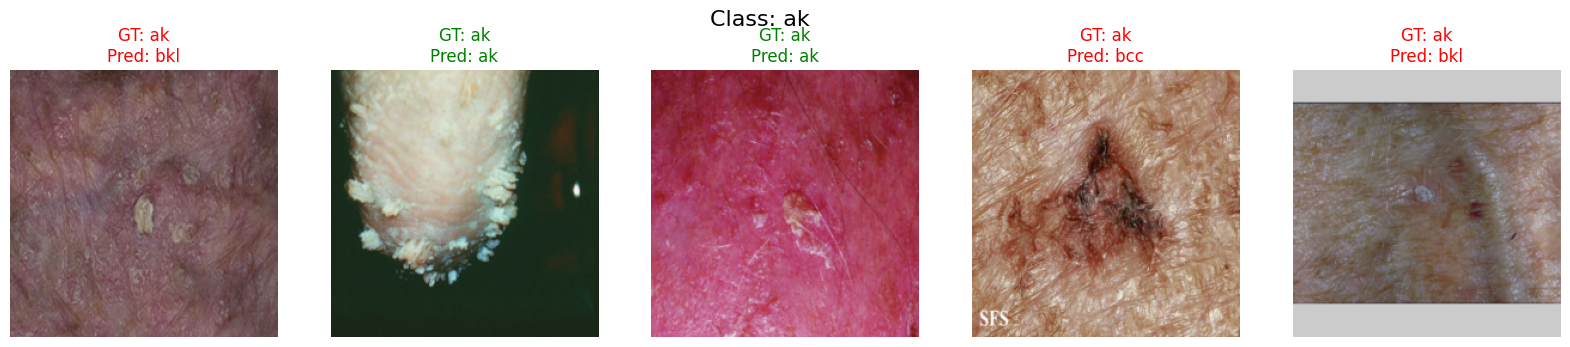

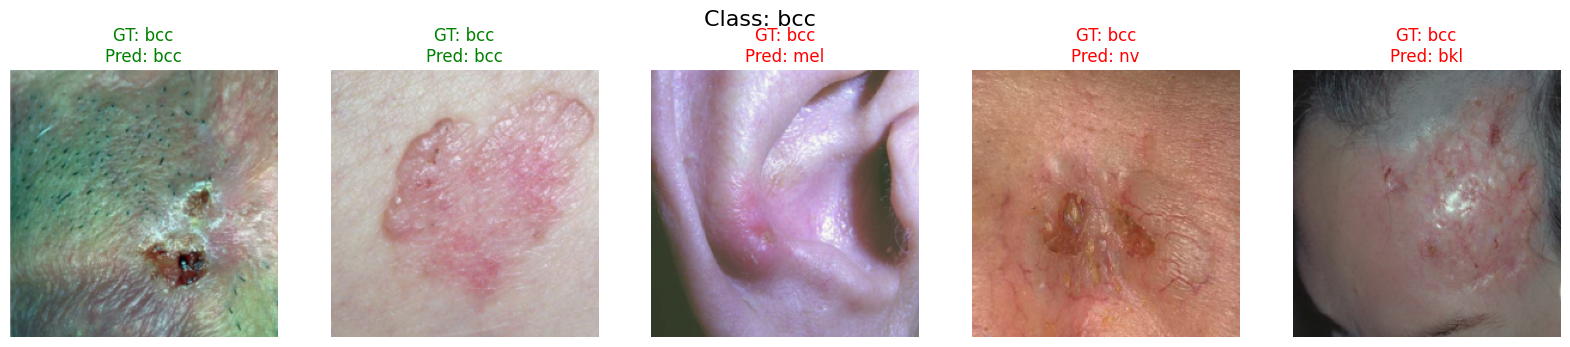

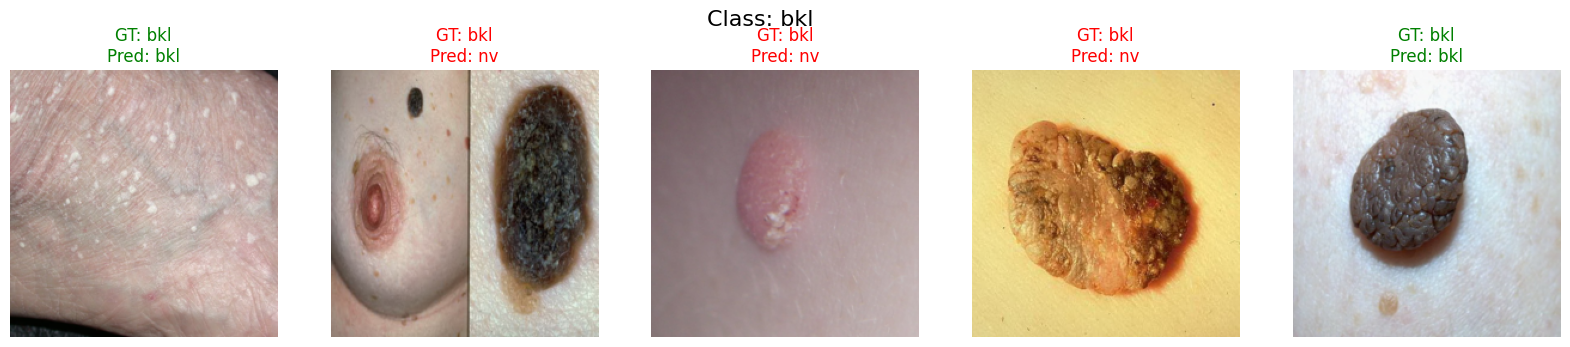

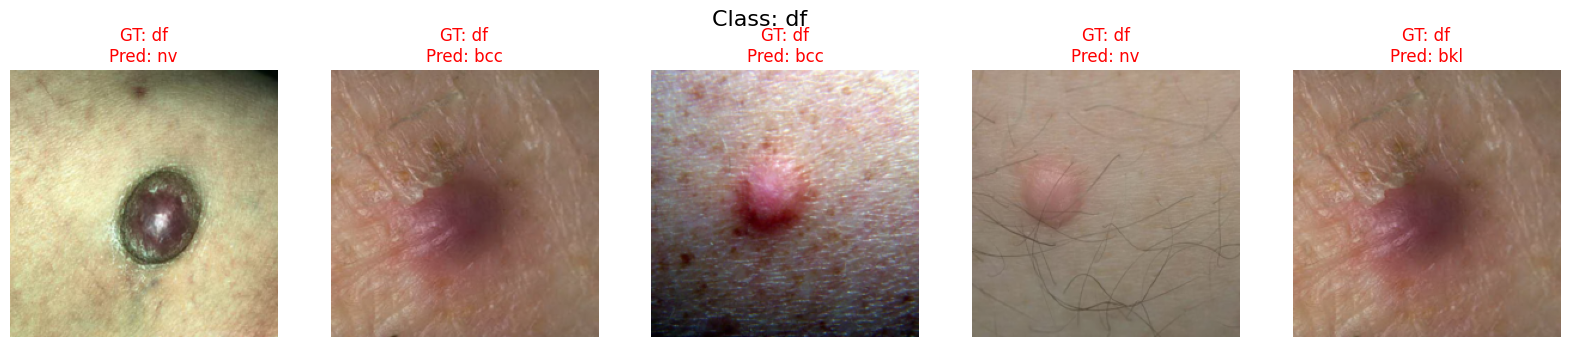

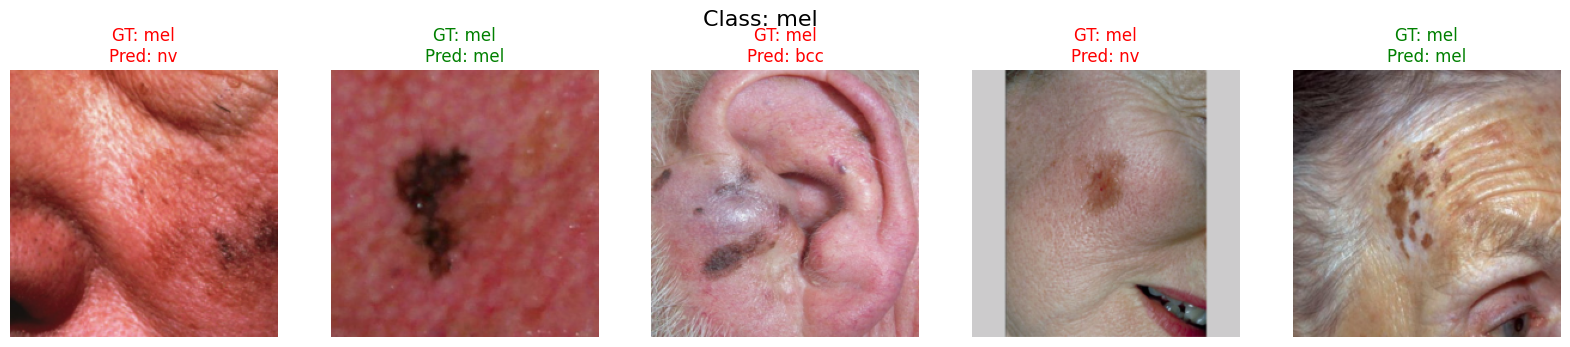

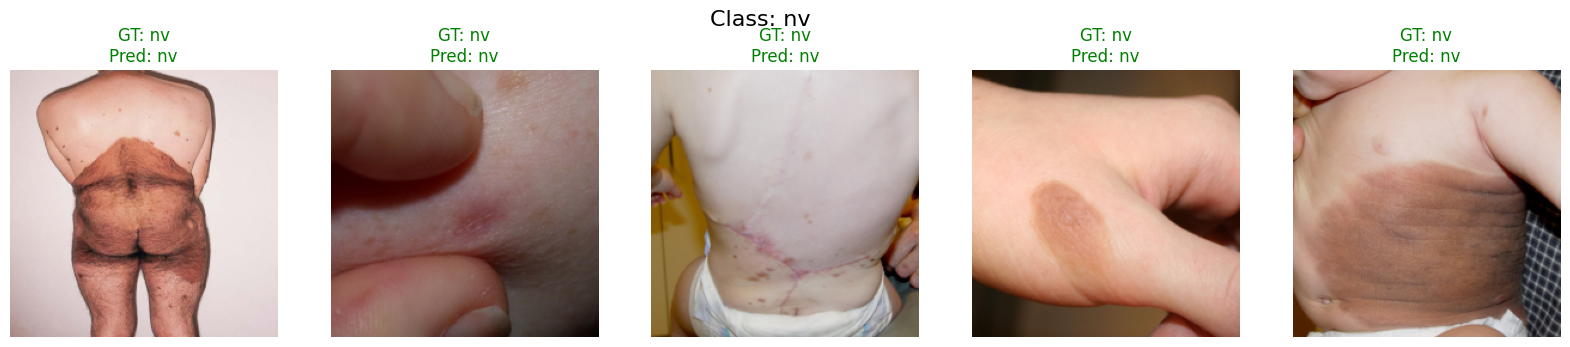

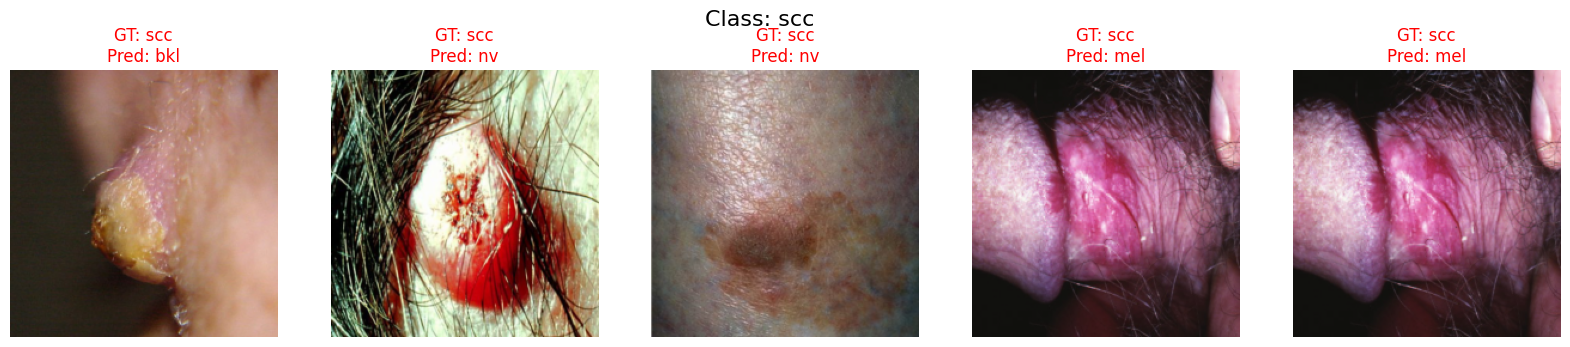

In [ ]:
from bsp_dann_mobilenetv2 import test_transform
from torchvision.datasets import ImageFolder
from torchvision import transforms

fitz_labeled_ds = ImageFolder(
    "/content/drive/MyDrive/Colab Notebooks/Domain Adaptation/fitz_selected",
    transform=test_transform
)

visualize_predictions_per_class(
    model=model,
    dataset=fitz_labeled_ds,
    class_names=fitz_labeled_ds.classes,
    samples_per_class=5,
    device=DEVICE
)
